In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

# Verify TPU connection
print("Available devices:", jax.devices())

# ==========================================
# 1. Parameter Definition & Multi-D Setup
# ==========================================
d = 10                   # Number of dimensions
num_directions = 2      # Number of random projection directions to save

sigma_val = 1.0
sigma = jnp.sqrt(sigma_val)
factor = 1.0
c = 1.0
beta_arr = jnp.array([0.3, 0.9])
K = 1e2

num_iters = 10000
num_paths = 200000
eval_interval = 50

chk_k = np.array([100, 200, 500, 1000, 5000, 10000])
chk_indices = (chk_k // eval_interval) - 1

# --- Generate Symmetric Matrix A ---
np.random.seed(42)
M = np.random.randn(d, d)
# Ensure A is symmetric and strictly positive definite (so -A is Hurwitz)
A_np = (M @ M.T) / d + np.eye(d)
A = jnp.array(A_np)

# --- Generate Random Projection Directions (Unit Vectors) ---
V_np = np.random.randn(d, num_directions)
V_np = V_np / np.linalg.norm(V_np, axis=0, keepdims=True)
V = jnp.array(V_np)

# ==========================================
# 2. Core JAX/TPU Simulation Function
# ==========================================
@jax.jit
def tpu_simulate_sa(beta, key):
    k_steps = jnp.arange(1, num_iters + 1)
    alphas = c / ((k_steps + K) ** beta)

    num_intervals = num_iters // eval_interval
    alphas_matrix = alphas.reshape((num_intervals, eval_interval))

    save_idx = jnp.full(num_intervals, -1)
    for i, idx in enumerate(chk_indices):
        save_idx = save_idx.at[idx].set(i)

    # Multi-D Initialization
    key = jax.random.PRNGKey(0)
    init_X = jax.random.normal(key, shape=(num_paths, d))

    # Checkpoint array now accounts for multiple projection directions
    init_saved_xs = jnp.zeros((len(chk_k), num_paths, num_directions))

    # --- INNER LOOP: Core SA Updates ---
    def inner_step(inner_carry, alpha_k):
        x, rng = inner_carry
        rng, key_u = jax.random.split(rng, 2)

        # Independent Laplace noise across all d dimensions
        noise_u = sigma * factor * jax.random.laplace(key_u, shape=(num_paths, d))

        # SA Update step: x_{k+1} = x_k - alpha_k * (A @ x_k) + alpha_k * noise
        # Note: x is (num_paths, d) and A is (d, d).
        # jnp.dot(x, A) elegantly applies the symmetric matrix A to all paths simultaneously.
        x_next = jnp.where(
            jnp.linalg.norm(x) >= 1.0,
            # (1.0 - alpha_k * A) * x + alpha_k * (jnp.sign(x) + noise_u),
            x - alpha_k * jnp.dot(x, A) + alpha_k * (x / jnp.linalg.norm(x) + noise_u),
            x - alpha_k * jnp.dot(x, A) + alpha_k * ((jnp.linalg.norm(x) ** (2.0 / 3.0)) * x + noise_u)
        )

        return (x_next, rng), None

    # --- OUTER LOOP: Periodic W1 Evaluation & Checkpointing ---
    def outer_step(outer_carry, inputs):
        x, rng, saved_xs = outer_carry
        alphas_chunk, s_idx = inputs

        (x_final, rng_final), _ = jax.lax.scan(inner_step, (x, rng), alphas_chunk)
        current_alpha = alphas_chunk[-1]

        # Scale the iterates
        scaled_x = x_final / jnp.sqrt(current_alpha)

        # Project the d-dimensional iterates onto the sampled unit vectors
        # Resulting shape: (num_paths, num_directions)
        projected_x = jnp.dot(scaled_x, V)

        def save_fn(saved):
            return jax.lax.dynamic_update_slice_in_dim(saved, projected_x[None, :, :], s_idx, axis=0)

        def skip_fn(saved):
            return saved

        saved_xs_next = jax.lax.cond(s_idx >= 0, save_fn, skip_fn, saved_xs)

        return (x_final, rng_final, saved_xs_next), None

    final_carry, _ = jax.lax.scan(outer_step, (init_X, key, init_saved_xs), (alphas_matrix, save_idx))
    return final_carry[2]

# ==========================================
# 3. Theoretical Covariance Tracker (Numpy)
# ==========================================
def compute_theoretical_covariance(beta, num_iters):
    """Deterministically tracks the exact unscaled d x d covariance matrix."""
    k_steps = np.arange(1, num_iters + 1)
    alphas = c / ((k_steps + K) ** beta)

    # Track full d x d covariance matrices
    sigmas = np.zeros((num_iters + 1, d, d))
    sigmas[0] = np.eye(d) / alphas[0]

    # Noise covariance matrix for independent Laplace distributions
    noise_variance = 2 * (sigma_val * factor)**2
    noise_cov = noise_variance * np.eye(d)
    I = np.eye(d)

    for k in range(num_iters):
        alpha_k = alphas[k]
        # Multi-D drift contraction matrix
        shrinkage = I - alpha_k * A_np + (beta / (2 * (k + K))) * I

        # Exact covariance update: \Sigma_{k+1} = M \Sigma_k M^T + \alpha_k \Sigma_{noise}
        sigmas[k+1] = shrinkage @ sigmas[k] @ shrinkage.T + alpha_k * noise_cov

    # Project the theoretically computed covariance matrix onto our sampled directions
    proj_variances = np.zeros((num_iters + 1, num_directions))
    for i in range(num_directions):
        v_i = V_np[:, i]
        # v^T \Sigma v gives the scalar variance along direction v
        proj_variances[:, i] = np.sum(v_i * (sigmas @ v_i), axis=-1)

    return alphas, proj_variances

# ==========================================
# 4. Execution
# ==========================================
vmap_simulate = jax.vmap(tpu_simulate_sa, in_axes=(0, 0))

master_key = jax.random.PRNGKey(42)
keys = jax.random.split(master_key, len(beta_arr))

print(f"Executing parallel simulation on TPU for {num_iters} steps with {num_paths} paths across {d} dimensions...")
all_saved_xs = vmap_simulate(beta_arr, keys)

# Block and transfer data to CPU memory
all_saved_xs = np.array(all_saved_xs)
# Output Shape: (len(beta), len(chk_k), num_paths, num_directions)
print("Simulation complete. Data shape:", all_saved_xs.shape)

/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


Available devices: [TpuDevice(id=0, process_index=0, coords=(0,0,0), core_on_chip=0)]
Executing parallel simulation on TPU for 10000 steps with 200000 paths across 10 dimensions...
Simulation complete. Data shape: (2, 6, 200000, 2)


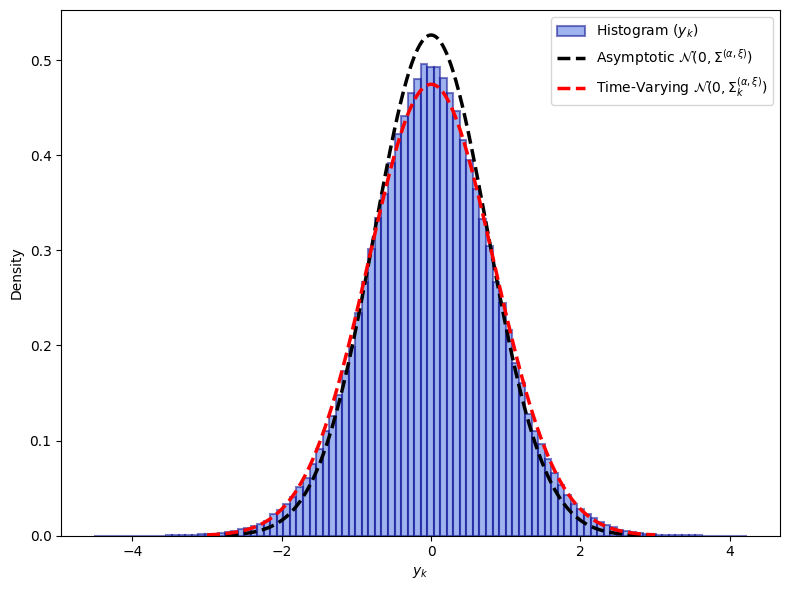

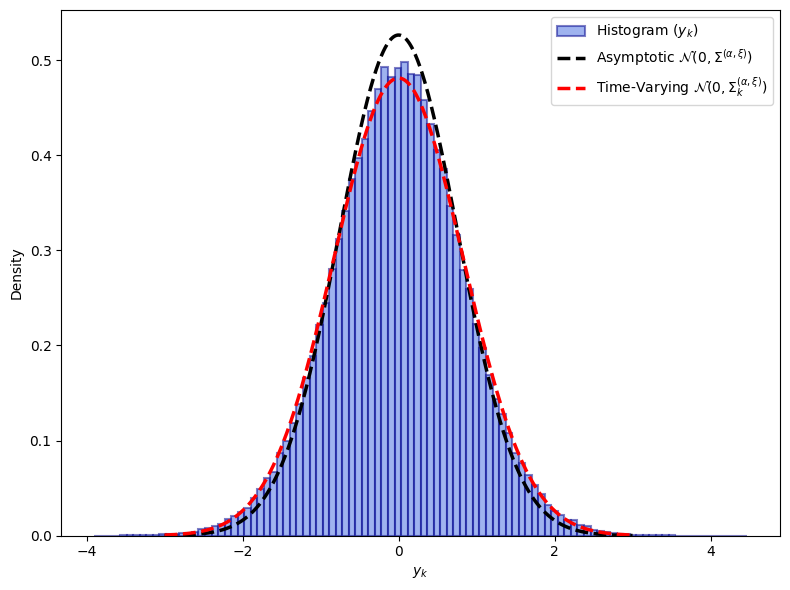

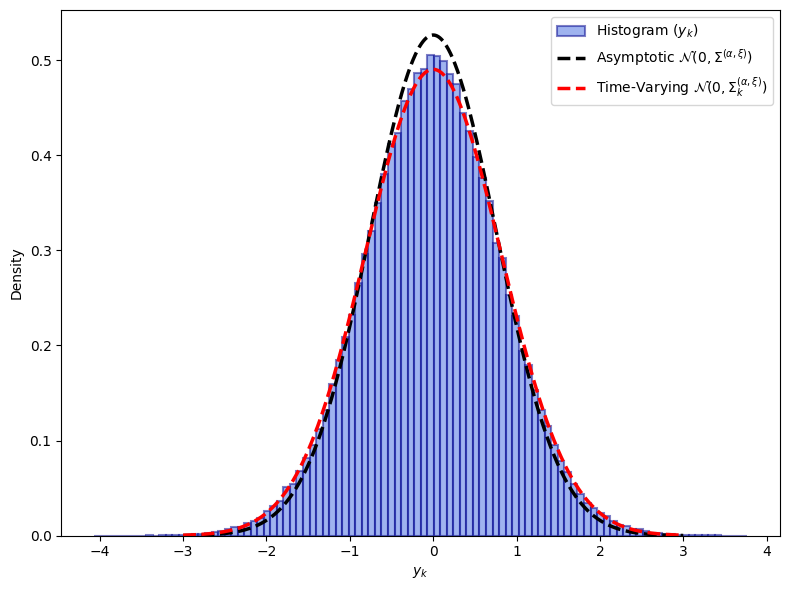

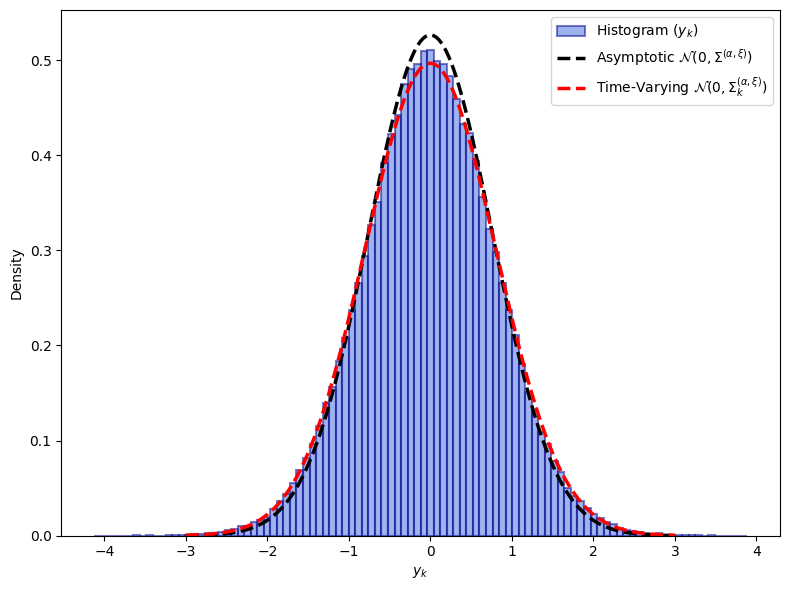

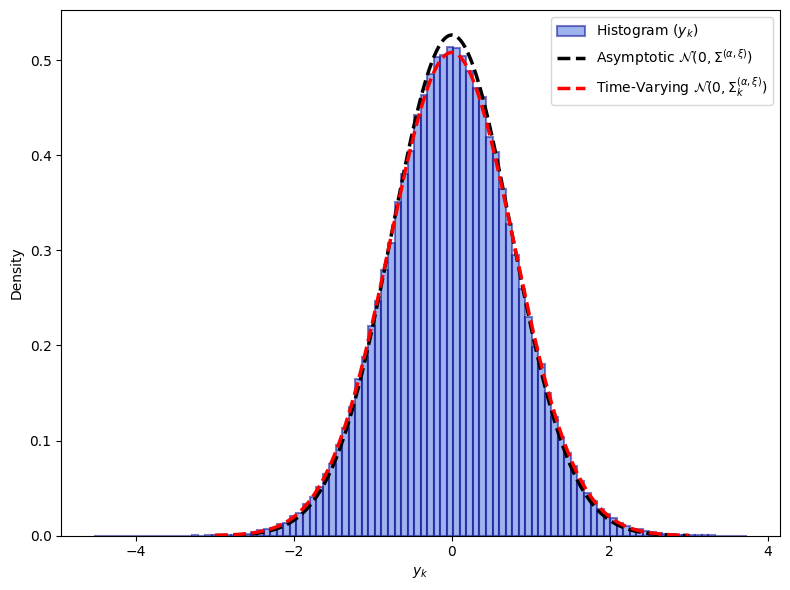

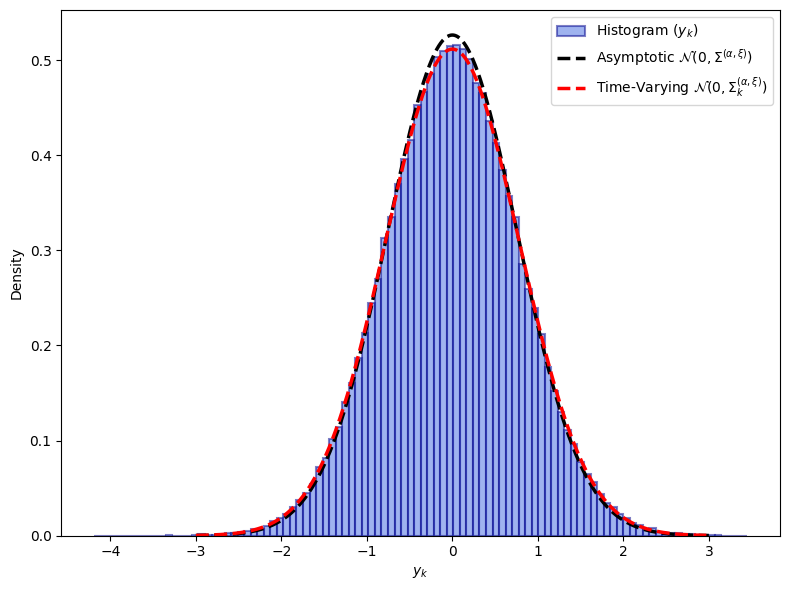

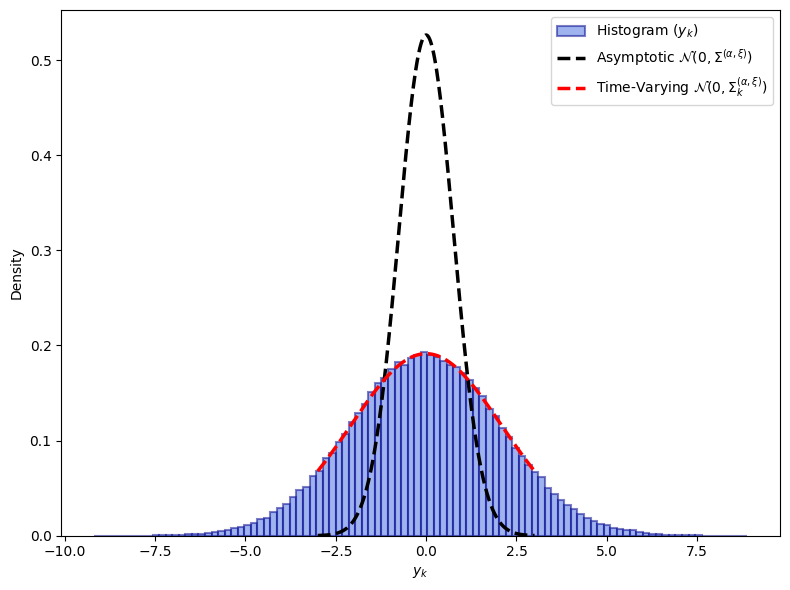

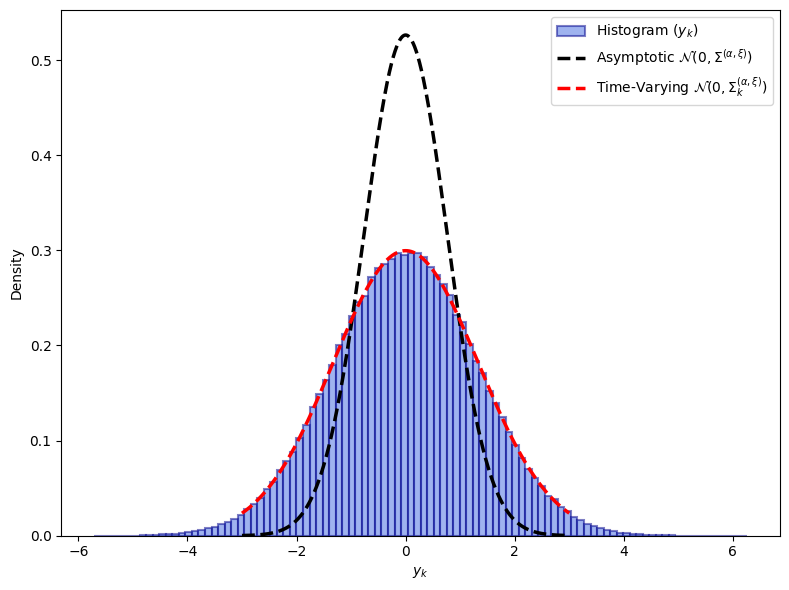

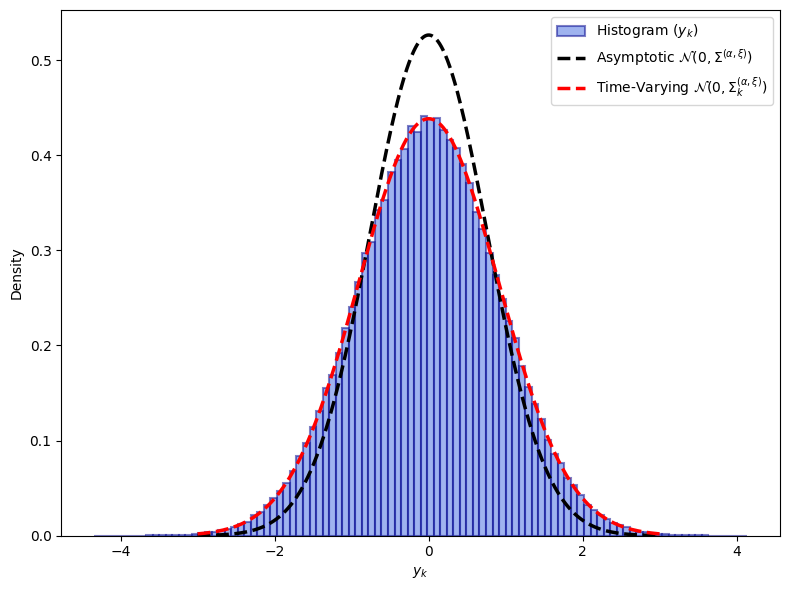

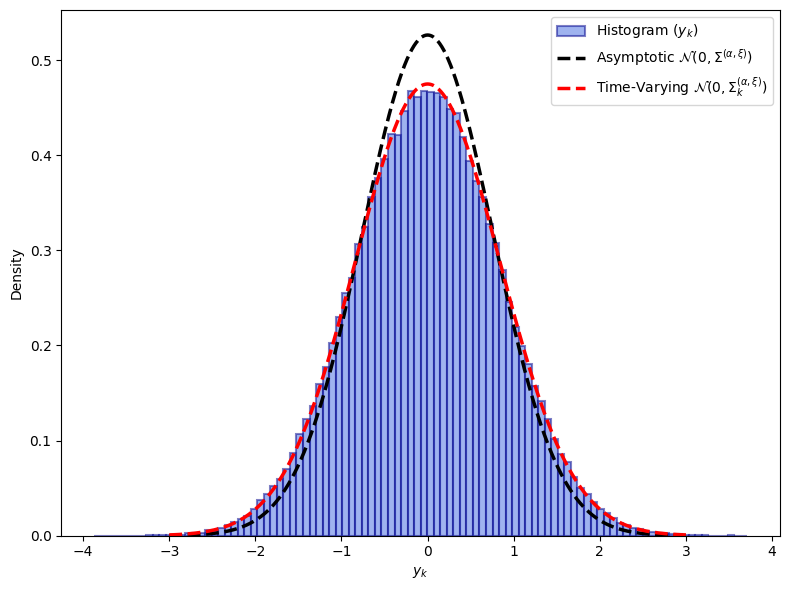

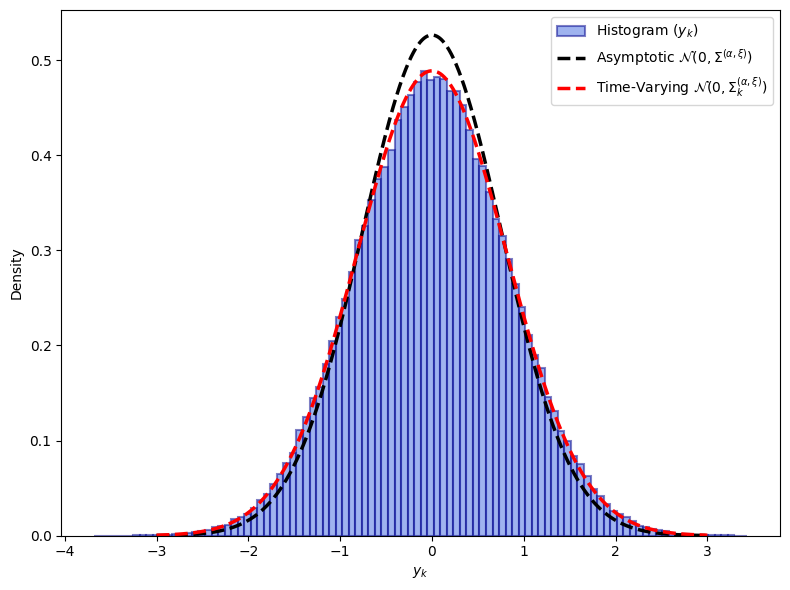

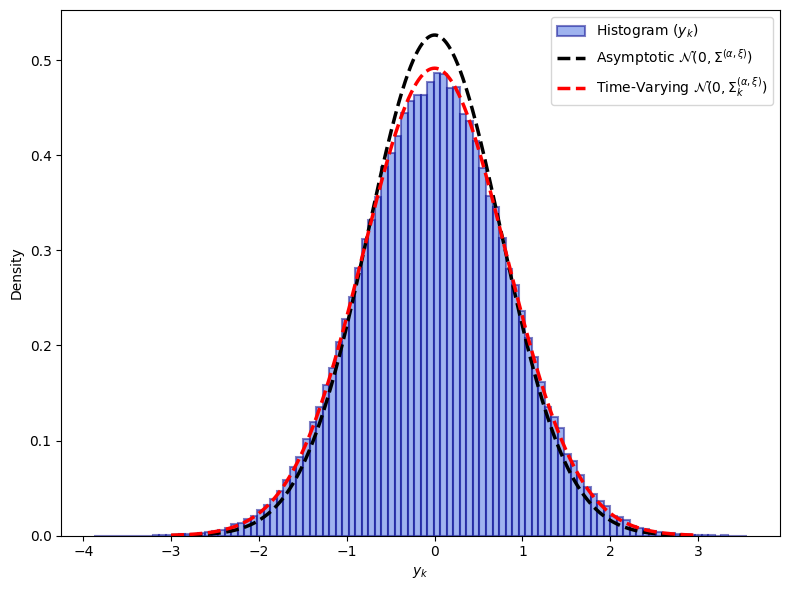

In [2]:
import scipy.stats as stats
# ==========================================
# 5. Plotting W1 Distances & Histograms
# ==========================================
k_values = np.arange(eval_interval, num_iters + 1, eval_interval)
off_set = 0
# ---------------------------------------
# PLOT 2: Overlay Histograms at Checkpoints
# ---------------------------------------
for idx, beta in enumerate(np.asarray(beta_arr)): ## Perform the calculations in numpy instead of JAX since it does a lot of approximation for speed
    # Calculate Theoretical Variances once for this beta
    beta = float(beta)
    alphas, sigmas = compute_theoretical_covariance(beta, num_iters)

    for i, k in enumerate(chk_k):
        # Create a new, separate figure for each checkpoint
        fig, ax = plt.subplots(figsize=(8, 6))

        # Subsample empirical data by 10 to speed up Matplotlib rendering
        empirical_data = all_saved_xs[idx, i, ::1, 0]

        # 1. Plot Empirical Histogram
        ax.hist(empirical_data, bins=100, density=True, alpha=0.5, color='royalblue',
                edgecolor='darkblue', linewidth=1.5, label=f'Histogram $(y_k)$')

        # Generate x_grid for PDFs
        x_grid = np.linspace(-3, 3, 1000)

        # 2. Plot Asymptotic PDF: N(0, sigma^2 / (2A))
        noise_variance = 2 * (sigma_val * factor)**2
        Sigma_inf = np.linalg.inv(A).dot(noise_variance) / 2
        asymptotic_std = np.sqrt(V[:, 0].T @ Sigma_inf @ V[:, 0])
        # asymptotic_std = np.sqrt(2 * (sigma_val**2) / (2 * A))
        pdf_asymp = stats.norm.pdf(x_grid, 0, asymptotic_std)
        ax.plot(x_grid, pdf_asymp, 'k--', linewidth=2.5, label=r'Asymptotic $\mathcal{N}(0, \Sigma^{(\alpha, \xi)})$')

        # 3. Plot Time-Varying PDF: N(0, Sigma_k / alpha_k)
        # current_alpha = alphas[k-1]
        current_sigma = sigmas[k, 0]
        current_std = np.sqrt(current_sigma)

        pdf_time = stats.norm.pdf(x_grid, 0, current_std)
        ax.plot(x_grid, pdf_time, 'r--', linewidth=2.5, label=r'Time-Varying $\mathcal{N}(0, \Sigma_k^{(\alpha, \xi)})$')

        # Combined title showing both Beta and Iteration K
        # ax.set_title(f'Distribution Evolution ($\\beta={beta:.2f}$) | Scaled Iterate at $k={k}$', fontsize=14)
        # ax.set_title(f'Distribution Evolution ($\\beta = {beta:.2f}$) | Scaled Iterate at $k = {k}$', fontsize=14)

        ax.set_xlabel('$y_k$')
        ax.set_ylabel('Density')
        ax.legend(loc='upper right')

        plt.tight_layout()
        plt.show() # Display the figure immediately